# Лабораторная работа 1. BPE и Unigram токенизаторы с нуля (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 1:** языковое моделирование и токенизация

**Цель.** Понять токенизацию как задачу сжатия и оценить, как выбор токенизатора влияет на последующую модель.

**Что нужно сдать:**
1. Реализацию byte-level BPE и Unigram LM токенизаторов без сторонних библиотек (кроме `re`, `collections`, `math`).
2. Тесты корректности: \(\mathrm{decode}(\mathrm{encode}(x)) = x\) на всём корпусе и на произвольных байтах.
3. Сравнение с `sentencepiece` (совпадение сегментаций, скорость).
4. Графики «размер словаря — степень сжатия» для русского и английского корпусов и ответы на вопросы.

**Теория, которую нужно уметь воспроизвести на защите.** BPE — жадный алгоритм сжатия: на каждом шаге в словарь добавляется пара символов с наибольшей частотой. Unigram LM задаёт вероятностную модель сегментации
\[
p(x) = \sum_{s \in S(x)} \prod_{i} p(s_i),
\]
где \(S(x)\) — множество разбиений строки на подслова. Параметры оцениваются EM-алгоритмом: E-шаг вычисляет ожидаемые числа вхождений подслов через прямой и обратный проход (forward-backward), M-шаг нормирует их. Кодирование — поиск самой вероятной сегментации алгоритмом Витерби.

In [1]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.14.0+cpu, device=cpu, FAST_DEV_RUN=True


## 0. Данные

Используем два корпуса: англоязычный (Tiny Shakespeare) и русскоязычный («Война и мир»). В режиме `FAST_DEV_RUN` корпуса обрезаются.

In [2]:
en_text = load_shakespeare()
ru_text = load_russian()
LIMIT = 200_000 if FAST_DEV_RUN else 2_000_000
en_text, ru_text = en_text[:LIMIT], ru_text[:LIMIT]
print(len(en_text), len(ru_text))
print(ru_text[5000:5300])

200000 200000
ступом согласие прусского короля. Вы так красноречивы. Вы дадите мне чаю?
- Сейчас. A propos,- прибавила она, опять успокоиваясь,- нынче у меня два очень интересные человека,  le vicomte de Mortemart, il est allié aux Montmorency par les Rohans, одна из лучших фамилий Франции. Это один из хороших эм


## 1. Byte-level BPE

Алгоритм обучения:
1. Разбить текст на «предтокены» регулярным выражением (слова с ведущим пробелом, числа, пунктуация), чтобы слияния не пересекали границы слов.
2. Представить каждый предтокен как последовательность байтов UTF-8 (идентификаторы 0–255).
3. Повторять `vocab_size - 256` раз: найти самую частую соседнюю пару, создать новый токен, заменить все вхождения пары.

Наивный пересчёт всех пар на каждом шаге стоит \(O(\text{корпус})\), поэтому храните счётчики пар и индекс «пара → предтокены, где она встречается», обновляя их только для затронутых предтокенов.

In [3]:
import re
from collections import Counter, defaultdict

PRETOKEN_RE = re.compile(r" ?[^\W\d_]+| ?\d{1,3}| ?[^\s\w]+| ?_+|\s+(?!\S)|\s+", re.UNICODE)

def pretokenize(text):
    return PRETOKEN_RE.findall(text)

assert "".join(pretokenize("Hello, мир! 12345  x")) == "Hello, мир! 12345  x"
print(pretokenize("Hello, мир! 12345  x"))

['Hello', ',', ' мир', '!', ' 123', '45', ' ', ' x']


In [4]:
def merge_word(word, pair, new_id):
    """Заменяет все вхождения pair в кортеже word на new_id (слева направо, без перекрытий)."""
    result = []
    i = 0
    while i < len(word):
        if i < len(word) - 1 and word[i] == pair[0] and word[i + 1] == pair[1]:
            result += [new_id]
            i += 2
        else:
            result += [word[i]]
            i += 1
    return tuple(result)

assert merge_word((1, 2, 3, 1, 2), (1, 2), 9) == (9, 3, 9)
assert merge_word((1, 1, 1), (1, 1), 7) == (7, 1)

In [5]:
class ByteBPE:
    def __init__(self):
        self.merges = {}                       # (a, b) -> new_id, порядок вставки = ранг
        self.vocab = {i: bytes([i]) for i in range(256)}
        self._cache = {}

    def train(self, text, vocab_size, verbose=False):
        assert vocab_size >= 256
        words = Counter(tuple(t.encode("utf-8")) for t in pretokenize(text))
        word_list = list(words.keys()); counts = [words[w] for w in word_list]

        pair_counts = Counter()
        pair_to_words = defaultdict(set)
        for idx, w in enumerate(word_list):
            for a, b in zip(w, w[1:]):
                pair_counts[(a, b)] += counts[idx]
                pair_to_words[(a, b)].add(idx)

        for step in range(vocab_size - 256):
            if not pair_counts:
                break
            best_pair = max(pair_counts, key=pair_counts.get)
            new_id = 256 + step
            self.merges[best_pair] = new_id
            self.vocab[new_id] = self.vocab[best_pair[0]] + self.vocab[best_pair[1]]

            changed = list(pair_to_words[best_pair])
            for idx in changed:
                old_w = word_list[idx]
                new_w = merge_word(old_w, best_pair, new_id)
                if old_w == new_w:
                    continue
                for a, b in zip(old_w, old_w[1:]):
                    pair_counts[(a, b)] -= counts[idx]
                    if pair_counts[(a, b)] <= 0:
                        del pair_counts[(a, b)]
                for a, b in zip(new_w, new_w[1:]):
                    pair_counts[(a, b)] += counts[idx]
                    pair_to_words[(a, b)].add(idx)
                word_list[idx] = new_w

            pair_to_words.pop(best_pair, None)
            if best_pair in pair_counts:
                del pair_counts[best_pair]
        self._cache = {}
        return self

    def _encode_chunk(self, chunk):
        if chunk in self._cache: return self._cache[chunk]
        ids = tuple(chunk.encode("utf-8"))
        while True:
            best_pair = None
            best_rank = np.inf
            for i in range(len(ids) - 1):
                pair = (ids[i], ids[i + 1])
                if pair in self.merges and self.merges[pair] < best_rank:
                    best_rank = self.merges[pair]
                    best_pair = pair
            if best_pair is None:
                break
            ids = merge_word(tuple(ids), best_pair, self.merges[best_pair])
        self._cache[chunk] = list(ids)
        return list(ids)

    def encode(self, text):
        out = []
        for ch in pretokenize(text): out.extend(self._encode_chunk(ch))
        return out

    def decode(self, ids):
        return b"".join(self.vocab[i] for i in ids).decode("utf-8", errors="replace")

t0 = time.time()
bpe_en = ByteBPE().train(en_text, 1000)
print(f"обучение: {time.time() - t0:.1f} c, токенов в словаре: {len(bpe_en.vocab)}")
print([bpe_en.vocab[i] for i in list(bpe_en.vocab)[256:276]])

обучение: 0.3 c, токенов в словаре: 1000
[b' t', b'he', b'ou', b' a', b' s', b' w', b're', b'ha', b' the', b'in', b' m', b'nd', b' b', b'er', b'it', b'is', b'or', b'on', b'll', b'es']


### Тесты корректности

Проверьте обратимость на всём корпусе, на тексте на другом языке, на эмодзи и на случайных байтах, декодированных как UTF-8 с заменой.

In [6]:
def check_roundtrip(tok, text):
    return tok.decode(tok.encode(text)) == text

assert check_roundtrip(bpe_en, en_text)
assert check_roundtrip(bpe_en, ru_text[:20000])
assert check_roundtrip(bpe_en, "Ёжик 🦔 и 数学 — test\t\n  ")
rnd = bytes(np.random.randint(0, 256, 5000).tolist()).decode("utf-8", errors="replace")
assert check_roundtrip(bpe_en, rnd)
print("Все тесты обратимости пройдены")

Все тесты обратимости пройдены


## 2. Unigram LM токенизатор

Работаем на уровне символов Unicode, пробел заменяем на `▁` и присоединяем к началу слова (как в SentencePiece).

1. **Начальный словарь:** все символы корпуса + самые частые подстроки длины 2…`max_len` (в несколько раз больше целевого размера).
2. **E-шаг:** для каждого слова прямой проход \(\alpha_j = \log\sum_{i<j} \exp(\alpha_i + \log p(x_{i:j}))\), обратный проход \(\beta\); ожидаемое число вхождений подслова \(x_{i:j}\) — \(\exp(\alpha_i + \log p(x_{i:j}) + \beta_j - \log Z)\), умноженное на частоту слова.
3. **M-шаг:** \(p(s) \propto \mathbb{E}[\text{count}(s)]\).
4. **Прунинг:** удалить долю подслов с наименьшей вероятностью (одиночные символы не удалять), повторять до целевого размера словаря.

Это упрощённая версия: SentencePiece удаляет подслова по приросту правдоподобия корпуса при их удалении, а не по вероятности.

In [ ]:
def logsumexp2(a, b):
    if a == -math.inf: return b
    if b == -math.inf: return a
    m = max(a, b); return m + math.log(math.exp(a - m) + math.exp(b - m))

def words_of(text):
    return Counter("▁" + w for w in text.split())

class UnigramTokenizer:
    def __init__(self, max_len=8):
        self.max_len = max_len; self.logp = {}

    def _forward_backward(self, w):
        """Возвращает (logZ, словарь ожидаемых вхождений подслов) для одного слова."""
        n = len(w)
        alpha = np.full(n + 1, -np.inf)
        alpha[0] = 0.0
        for j in range(1, n + 1):
            for i in range(max(0, j - self.max_len), j):
                sub = w[i:j]
                if sub in self.logp and alpha[i] != -math.inf:
                    alpha[j] = logsumexp2(alpha[j], alpha[i] + self.logp[sub])

        beta = np.full(n + 1, -np.inf)
        beta[n] = 0.0
        for i in range(n - 1, -1, -1):
            for j in range(i + 1, min(n, i + self.max_len) + 1):
                sub = w[i:j]
                if sub in self.logp and beta[j] != -math.inf:
                    beta[i] = logsumexp2(beta[i], self.logp[sub] + beta[j])

        logZ = alpha[n]
        if logZ == -math.inf:
            return logZ, {}
        
        expected = {}
        for i in range(n):
            if alpha[i] == -math.inf:
                continue
            for j in range(i + 1, min(n, i + self.max_len) + 1):
                sub = w[i:j]
                if sub in self.logp and beta[j] != -math.inf:
                    e = math.exp(alpha[i] + self.logp[sub] + beta[j] - logZ)
                    expected[sub] = expected.get(sub, 0.0) + e
        return logZ, expected

    def train(self, text, vocab_size, init_factor=4, prune_frac=0.2, em_iters=2, verbose=True):
        words = words_of(text)
        chars = Counter(); subs = Counter()
        for w, c in words.items():
            for ch in w: chars[ch] += c
            for i in range(len(w)):
                for j in range(i + 2, min(len(w), i + self.max_len) + 1):
                    subs[w[i:j]] += c
        init = dict(chars); init.update(dict(subs.most_common(init_factor * vocab_size)))
        total = sum(init.values()); self.logp = {s: math.log(c / total) for s, c in init.items()}
        self.chars = set(chars)
        while True:
            for _ in range(em_iters):
                expected_counts = defaultdict(float)
                ll = 0.0
                for w, c in words.items():
                    logZ, exp = self._forward_backward(w)
                    if logZ == -math.inf:
                        continue
                    ll += c * logZ
                    for s, e in exp.items():
                        expected_counts[s] += c * e
                total = sum(expected_counts.values())
                self.logp = {s: math.log(e / total) for s, e in expected_counts.items() if e > 0}
            if verbose: print(f"|V|={len(self.logp):6d}  log-likelihood={ll:.4e}")
            if len(self.logp) <= vocab_size: break

            candidates = [(s, p) for s, p in self.logp.items() if len(s) > 1]
            candidates.sort(key=lambda x: x[1])
            n_remove = min(int(len(self.logp) * prune_frac), len(self.logp) - vocab_size)
            for s, _ in candidates[:n_remove]:
                del self.logp[s]
        return self

    def segment(self, w):
        """Витерби: самая вероятная сегментация слова."""
        n = len(w)
        best = np.full(n + 1, -np.inf)
        best[0] = 0.0
        back = [-1] * (n + 1)
        for j in range(1, n + 1):
            for i in range(max(0, j - self.max_len), j):
                sub = w[i:j]
                if sub in self.logp and best[i] != -math.inf:
                    score = best[i] + self.logp[sub]
                    if score > best[j]:
                        best[j] = score
                        back[j] = i
        pieces = []
        j = n
        while j > 0:
            i = back[j]
            if i < 0:
                pieces.append(w[j - 1])
                j -= 1
            else:
                pieces.append(w[i:j])
                j = i
        return pieces[::-1]

    def encode(self, text):
        out = []
        for part in re.split(r"(\s+)", text):
            if not part: continue
            if part.isspace():
                if part == " ": continue
                out.append(part)
            else:
                out.extend(self.segment("▁" + part))
        return out

    def decode(self, pieces):
        s, prev_ws = "", True
        for p in pieces:
            if p.startswith("▁"):
                s += ("" if prev_ws else " ") + p[1:]; prev_ws = False
            else:
                s += p; prev_ws = p.isspace()
        return s

t0 = time.time()
uni_en = UnigramTokenizer().train(en_text[: (60_000 if FAST_DEV_RUN else 500_000)], 1000)
print(f"обучение: {time.time() - t0:.1f} c")
print(uni_en.encode("To be, or not to be: that is the question."))

|V|=  4058  log-likelihood=-1.1196e+05
|V|=  3247  log-likelihood=-1.0939e+05
|V|=  2598  log-likelihood=-1.0916e+05
|V|=  2079  log-likelihood=-1.0906e+05
|V|=  1664  log-likelihood=-1.0905e+05
|V|=  1332  log-likelihood=-1.0987e+05
|V|=  1066  log-likelihood=-1.1133e+05
|V|=  1000  log-likelihood=-1.1168e+05
обучение: 2.7 c
['▁To', '▁be', ',', '▁or', '▁not', '▁to', '▁be', ':', '▁that', '▁is', '▁the', '▁qu', 'es', 'tion', '.']


**Замечание об обратимости.** Наш Unigram-токенизатор работает с токенами-строками, а не с байтами. Обратимость гарантирована для текстов из одиночных пробелов между словами; проверьте её на корпусе, нормализованном так, как это делает SentencePiece (подряд идущие пробелы сжаты, переводы строк сохранены).

In [8]:
def normalize_spaces(t):
    t = re.sub(r"[ \t]+", " ", t)
    return re.sub(r" *\n *", "\n", t).strip()

sample = normalize_spaces(en_text[:20000])
assert uni_en.decode(uni_en.encode(sample)) == sample
print("Unigram: обратимость на нормализованном корпусе выполнена")

Unigram: обратимость на нормализованном корпусе выполнена


## 3. Сравнение с SentencePiece

Обучите `sentencepiece` в режимах `bpe` и `unigram` с тем же размером словаря и сравните:
- долю слов, сегментированных одинаково с вашей реализацией;
- среднее число токенов на слово;
- время обучения и кодирования.

Полного совпадения ожидать не нужно: SentencePiece использует другой прунинг, нормализацию и обработку редких символов.

In [11]:
try:
    import sentencepiece as spm
except ImportError:
    os.system("pip -q install sentencepiece"); import sentencepiece as spm

corpus_file = DATA / "en_corpus.txt"; corpus_file.write_text(en_text, encoding="utf-8")
spm_models = {}
for mtype in ("bpe", "unigram"):
    t0 = time.time()
    spm.SentencePieceTrainer.train(input=str(corpus_file), model_prefix=str(ARTIFACTS / f"spm_{mtype}"),
                                   vocab_size=1000, model_type=mtype, character_coverage=1.0,
                                   max_sentence_length=100000, minloglevel=2)
    spm_models[mtype] = spm.SentencePieceProcessor(model_file=str(ARTIFACTS / f"spm_{mtype}.model"))
    print(mtype, f"обучение {time.time() - t0:.1f} c")

bpe обучение 0.1 c
unigram обучение 0.2 c


In [12]:
def agreement(seg_a, seg_b, words):
    same = sum(seg_a(w) == seg_b(w) for w in words)
    return same / len(words)

test_words = [w for w, _ in words_of(en_text[150_000:]).most_common(2000)]
ours_uni = lambda w: uni_en.segment(w)
sp_uni = lambda w: [p for p in spm_models["unigram"].encode(w[1:], out_type=str)]
ours_bpe = lambda w: [bpe_en.vocab[i].decode("utf-8", "replace") for i in bpe_en.encode(" " + w[1:])]
sp_bpe = lambda w: [p.replace("▁", " ") for p in spm_models["bpe"].encode(w[1:], out_type=str)]

# Agreement
print(f"Unigram agreement: {agreement(ours_uni, sp_uni, test_words):.2%}")
print(f"BPE agreement: {agreement(ours_bpe, sp_bpe, test_words):.2%}")

# Токенов на слово
print(f"Unigram tokens/word: ours={np.mean([len(ours_uni(w)) for w in test_words]):.2f}, "
      f"sp={np.mean([len(sp_uni(w)) for w in test_words]):.2f}")
print(f"BPE tokens/word: ours={np.mean([len(ours_bpe(w)) for w in test_words]):.2f}, "
      f"sp={np.mean([len(sp_bpe(w)) for w in test_words]):.2f}")

# Время кодирования
t0 = time.time()
for w in test_words: ours_uni(w)
t_uni_ours = time.time() - t0
t0 = time.time()
for w in test_words: sp_uni(w)
t_uni_sp = time.time() - t0
t0 = time.time()
for w in test_words: ours_bpe(w)
t_bpe_ours = time.time() - t0
t0 = time.time()
for w in test_words: sp_bpe(w)
t_bpe_sp = time.time() - t0

print(f"Unigram encode time: ours={t_uni_ours:.3f}s, sp={t_uni_sp:.3f}s")
print(f"BPE encode time: ours={t_bpe_ours:.3f}s, sp={t_bpe_sp:.3f}s")

Unigram agreement: 36.65%
BPE agreement: 72.75%
Unigram tokens/word: ours=2.87, sp=2.92
BPE tokens/word: ours=3.15, sp=2.87
Unigram encode time: ours=0.020s, sp=0.006s
BPE encode time: ours=0.005s, sp=0.008s


## 4. Размер словаря, язык и степень сжатия

Для словарей 1k, 8k, 32k (в `FAST_DEV_RUN`: 300, 1000, 2000) обучите BPE на английском и русском корпусах и измерьте на отложенной части:
- **fertility** — среднее число токенов на слово;
- **сжатие** — байтов UTF-8 на токен;
- **долю редких токенов** — долю токенов словаря, встретившихся в отложенной части менее 5 раз.

Обучающая и отложенная части не должны пересекаться.

In [13]:
VOCABS = [300, 1000, 2000] if FAST_DEV_RUN else [1000, 8000, 32000]

def tokenizer_stats(tok, text, vocab_size):
    ids = tok.encode(text)
    words = [w for w in text.split() if w]
    fertility = len(ids) / max(len(words), 1)

    n_bytes = len(text.encode("utf-8"))
    bytes_per_token = n_bytes / max(len(ids), 1)

    cnt = Counter(ids)
    rare = sum(1 for i in tok.vocab if cnt[i] < 5)
    rare_share = rare / vocab_size

    return {"fertility": fertility, "bytes_per_token": bytes_per_token, "rare_share": rare_share}

results = {}
for lang, text in [("en", en_text), ("ru", ru_text)]:
    cut = int(0.8 * len(text)); train_t, test_t = text[:cut], text[cut:]
    for V in VOCABS:
        tok = ByteBPE().train(train_t, V)
        results[(lang, V)] = tokenizer_stats(tok, test_t, len(tok.vocab))
        print(lang, V, {k: round(v, 3) for k, v in results[(lang, V)].items()})

en 300 {'fertility': 4.062, 'bytes_per_token': 1.371, 'rare_share': 0.657}
en 1000 {'fertility': 2.505, 'bytes_per_token': 2.223, 'rare_share': 0.476}
en 2000 {'fertility': 2.108, 'bytes_per_token': 2.643, 'rare_share': 0.725}
ru 300 {'fertility': 5.543, 'bytes_per_token': 1.942, 'rare_share': 0.557}
ru 1000 {'fertility': 2.778, 'bytes_per_token': 3.875, 'rare_share': 0.394}
ru 2000 {'fertility': 2.294, 'bytes_per_token': 4.692, 'rare_share': 0.639}


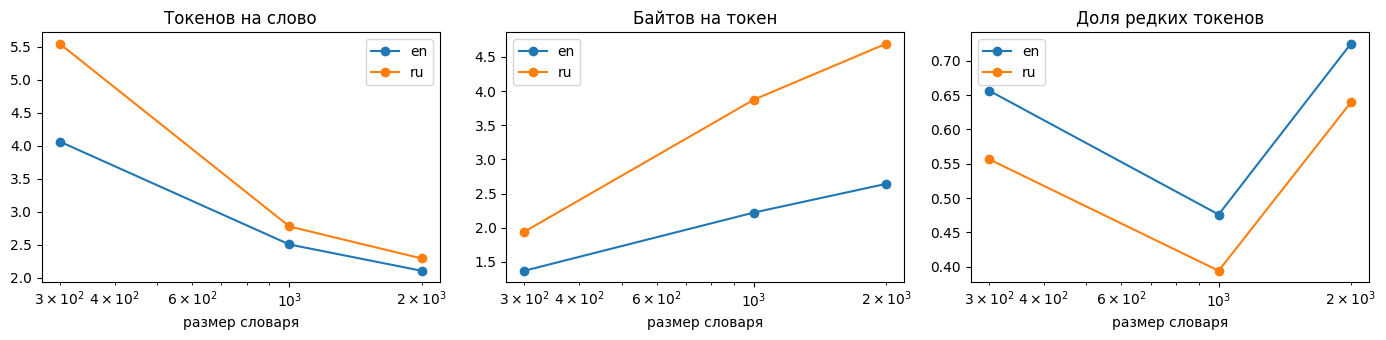

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, key, title in zip(axes, ["fertility", "bytes_per_token", "rare_share"],
                          ["Токенов на слово", "Байтов на токен", "Доля редких токенов"]):
    for lang in ("en", "ru"):
        ax.plot(VOCABS, [results[(lang, V)][key] for V in VOCABS], "o-", label=lang)
    ax.set_xscale("log"); ax.set_xlabel("размер словаря"); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.savefig(ARTIFACTS / "lab01_vocab_curves.png", dpi=120); plt.show()

## 5. Токенизация чисел и кода

Посмотрите, как токенизатор разбивает числа разной длины и фрагменты кода. Найдите примеры, где одно и то же число разбивается по-разному в зависимости от контекста (с пробелом и без), и объясните, почему это мешает модели выполнять арифметику.

In [15]:
examples = ["12345 + 67890 = 80235", "x12345", " 1000000", "3.14159", "def f(x):\n    return x**2"]
for e in examples:
    print(repr(e), "->", [bpe_en.vocab[i].decode("utf-8", "replace") for i in bpe_en.encode(e)])

'12345 + 67890 = 80235' -> ['1', '2', '3', '4', '5', ' ', '+', ' ', '6', '7', '8', '9', '0', ' ', '=', ' ', '8', '0', '2', '3', '5']
'x12345' -> ['x', '1', '2', '3', '4', '5']
' 1000000' -> [' ', '1', '0', '0', '0', '0', '0', '0']
'3.14159' -> ['3', '.', '1', '4', '1', '5', '9']
'def f(x):\n    return x**2' -> ['de', 'f', ' f', '(', 'x', ')', ':', '\n', ' ', ' ', ' ', ' re', 't', 'urn', ' ', 'x', '*', '*', '2']


## Вопросы

1. Почему BPE-обучение можно рассматривать как жадный алгоритм сжатия? Что он оптимизирует на каждом шаге и почему результат не оптимален глобально?
2. Почему при одинаковом размере словаря русский текст даёт больше токенов на слово, чем английский? Как это влияет на стоимость инференса и эффективную длину контекста?
3. Чем Unigram LM лучше BPE с вероятностной точки зрения? Что даёт возможность сэмплировать сегментации (subword regularization)?
4. Почему perplexity моделей с разными токенизаторами нельзя сравнивать напрямую и как перейти к bits-per-byte?
5. Предложите способ токенизации чисел, облегчающий арифметику, и обоснуйте его.